# Deliverable 2 – FIFA 21 Player Analysis

**Name:** Antriksh Gupta  
**Class:** CIS 3400  
**Dataset:** FIFA 2021 Complete Player Dataset (`FIFA-21 Complete.csv`)  
**Second file:** `fifa_confederations.csv` (nationality, FIFA confederation, and region)  
**Source:** [Kaggle – FIFA 2021 Complete Player Data](https://www.kaggle.com/datasets/aayushmishra1512/fifa-2021-complete-player-data) (CC0). Ratings originally come from fifaindex.com.

This notebook is Deliverable 2 for my Streamlit dashboard project. I am using the FIFA 21 player file from my proposal. The people who would use the dashboard are football fans and FIFA players (Career Mode / Ultimate Team) who want to compare ratings, age, countries, clubs, and positions.

From the files / time / merges class notebook, I used three things here: I ask for the CSV path instead of hard-coding `C:\\Users\\...`, I added `assert` checks after I load and merge, and I merge in a second file on nationality.

The three questions from my proposal:

1. **Q1 – Age:** How do overall rating and potential change with age, and at what age do players peak or stop growing?
2. **Q2 – Country and club:** Which nationalities and clubs have the highest-rated players, once small groups are excluded?
3. **Q3 – Position:** How do ratings and growth potential differ by position, and which positions have the most room to grow?

### Contents
1. Load and understand the data
2. Clean, add columns, and merge a second file
3. Descriptive statistics and distributions
4. Explore the data and answer the three questions
5. Charts (the ones I want in the dashboard)
6. Which three charts I am keeping
7. Save the dashboard CSV
8. Notes for the Streamlit app later


---
## 1. Load and understand the data

### 1.1 Import libraries


In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DEFAULT_RAW = "FIFA-21 Complete.csv"
CONFED_FILE = "fifa_confederations.csv"
DASHBOARD_FILE = "dashboard_data.csv"


def ask_for_file(prompt="Path to the FIFA CSV (press Enter for FIFA-21 Complete.csv): ",
                 default=DEFAULT_RAW, suffixes=(".csv",)):
    """Ask for a path so this notebook works on another computer. Enter uses the default."""
    while True:
        try:
            text = input(prompt).strip().strip("\"'")
        except Exception:
            # no prompt available (for example Run All in some setups) -> use the default
            text = ""
        path = Path(text).expanduser() if text else Path(default)
        if not path.is_file():
            print(f"  Not found: {path}")
            if text == "":
                raise ValueError(f"Default file not found: {path}")
        elif path.suffix.lower() not in suffixes:
            print(f"  Expected one of {suffixes}, got {path.suffix!r}")
        else:
            return path


### 1.2 Load the data
Hard-coding `C:\\Users\\...` would break this notebook on another computer, so I ask for the path. Press Enter to use `FIFA-21 Complete.csv` in the same folder. The Kaggle file is separated by semicolons, not commas. I keep `df_raw` as the original so I can compare it after cleaning.

`assert` is for my own assumptions (file loaded, columns I expect, unique IDs). If the file is missing I raise `ValueError` instead.


In [2]:
raw_path = ask_for_file()
df_raw = pd.read_csv(raw_path, sep=";", encoding="utf-8-sig")

needed = ["player_id", "name", "nationality", "position", "overall", "age", "hits", "potential", "team"]
assert isinstance(df_raw, pd.DataFrame), f"expected a DataFrame, got {type(df_raw).__name__}"
assert len(df_raw) > 1000, f"file looks too small: {len(df_raw)} rows"
assert set(needed).issubset(df_raw.columns), f"missing columns: {set(needed) - set(df_raw.columns)}"

print("Loaded", raw_path, "->", f"{df_raw.shape[0]:,}", "rows,", df_raw.shape[1], "columns")
df_raw.head(8)


Loaded FIFA-21 Complete.csv -> 17,981 rows, 9 columns


,player_id,name,nationality,position,overall,age,hits,potential,team
0,158023,Lionel Messi,Argentina,ST|CF|RW,94,33,299,94,FC Barcelona
1,20801,Cristiano Ronaldo,Portugal,ST|LW,93,35,276,93,Juventus
2,190871,Neymar Jr,Brazil,CAM|LW,92,28,186,92,Paris Saint-Germain
3,203376,Virgil van Dijk,Netherlands,CB,91,29,127,92,Liverpool
4,200389,Jan Oblak,Slovenia,GK,91,27,47,93,Atlético Madrid
5,192985,Kevin De Bruyne,Belgium,CM|CAM,91,29,119,91,Manchester City
6,188545,Robert Lewandowski,Poland,ST,91,31,89,91,FC Bayern München
7,183277,Eden Hazard,Belgium,ST|LW,91,29,66,91,Real Madrid


### 1.3 Columns, types, and record counts


In [3]:
print(df_raw.dtypes)
print()
df_raw.info()


player_id      int64
name             str
nationality      str
position         str
overall        int64
age            int64
hits           int64
potential      int64
team             str
dtype: object

<class 'pandas.DataFrame'>
RangeIndex: 17981 entries, 0 to 17980
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   player_id    17981 non-null  int64
 1   name         17981 non-null  str  
 2   nationality  17981 non-null  str  
 3   position     17981 non-null  str  
 4   overall      17981 non-null  int64
 5   age          17981 non-null  int64
 6   hits         17981 non-null  int64
 7   potential    17981 non-null  int64
 8   team         17981 non-null  str  
dtypes: int64(5), str(4)
memory usage: 1.9 MB


In [4]:
df_raw.describe()


,player_id,overall,age,hits,potential
count,"17,981.00","17,981.00","17,981.00","17,981.00","17,981.00"
mean,"220,912.66",67.27,26.31,2.69,71.74
std,"27,738.07",5.92,4.56,10.85,5.96
min,41.00,56.00,17.00,0.00,57.00
25%,"204,881.00",63.00,23.00,0.00,67.00
50%,"226,753.00",67.00,26.00,0.00,71.00
75%,"241,587.00",71.00,30.00,2.00,76.00
max,"256,469.00",94.00,43.00,371.00,95.00


### 1.4 Data dictionary

| Column | Meaning |
|---|---|
| `player_id` | Unique player ID |
| `name` | Player name |
| `nationality` | Country |
| `position` | Positions the player can play, separated by `\|` |
| `overall` | Current FIFA rating |
| `age` | Age in years |
| `hits` | Number from fifaindex.com. The Kaggle page does not really explain it. |
| `potential` | How high the rating can still go |
| `team` | Club name, or Free Agents |

These are video game ratings, not real match stats.


### 1.5 Data quality checks
I am checking missing values, duplicates, messy text, and values that do not make sense.


In [5]:
print("Missing values:")
print(df_raw.isna().sum())
print()
print("Exact duplicate rows:", df_raw.duplicated().sum())
print("Duplicate player IDs:", df_raw["player_id"].duplicated().sum())
print("Duplicate names:", df_raw["name"].duplicated().sum())
print()
print("Unique nationalities:", df_raw["nationality"].nunique())
print("Unique teams:", df_raw["team"].nunique())
print("Unique position strings:", df_raw["position"].nunique())


Missing values:
player_id      0
name           0
nationality    0
position       0
overall        0
age            0
hits           0
potential      0
team           0
dtype: int64

Exact duplicate rows: 0
Duplicate player IDs: 0
Duplicate names: 280

Unique nationalities: 162
Unique teams: 713
Unique position strings: 232


In [6]:
print("Age:", df_raw["age"].min(), "to", df_raw["age"].max())
print("Overall:", df_raw["overall"].min(), "to", df_raw["overall"].max())
print("Potential:", df_raw["potential"].min(), "to", df_raw["potential"].max())
print("Rows where potential is lower than overall:", (df_raw["potential"] < df_raw["overall"]).sum())
print()
print("Team names with extra spaces:", (df_raw["team"] != df_raw["team"].str.strip()).sum())
print("Example team values:", [repr(x) for x in df_raw["team"].head(4)])
print()
print("hits = 0:", (df_raw["hits"] == 0).sum())
print("hits > 0:", (df_raw["hits"] > 0).sum())
print("Free Agents:", df_raw["team"].str.strip().eq("Free Agents").sum())


Age: 17 to 43
Overall: 56 to 94
Potential: 57 to 95
Rows where potential is lower than overall: 0

Team names with extra spaces: 17956
Example team values: ["'FC Barcelona '", "'Juventus '", "'Paris Saint-Germain '", "'Liverpool '"]

hits = 0: 9718
hits > 0: 8263
Free Agents: 211


In [7]:
print("Players by nationality (top 10):")
print(df_raw["nationality"].value_counts().head(10))
print()
print("First position listed:")
print(df_raw["position"].str.split("|").str[0].value_counts())


Players by nationality (top 10):
nationality
England        1496
Germany        1138
Spain          1055
Argentina       970
France          948
Brazil          894
Italy           637
Colombia        561
Japan           448
Netherlands     418
Name: count, dtype: int64

First position listed:


position
ST     3216
CB     2777
CDM    2176
GK     1885
RB     1805
LB     1665
RM     1443
CM     1145
LM      743
CAM     412
RWB     321
RW      222
LW       76
LWB      57
CF       38
Name: count, dtype: int64


### 1.6 What I found

| Issue | What I saw | What I will do |
|---|---|---|
| Semicolon file | The CSV uses `;` | Load with `sep=";"` |
| Extra spaces on team | Almost every team name looks like `"FC Barcelona "` | Strip the spaces |
| Position is a combo | 232 different strings like `ST\|RW` | Keep it, but add a primary position column |
| `hits` is mostly 0 | 9,718 players have 0 hits and the meaning is unclear | I will not use hits in the analysis |
| Same names | 280 names repeat, but IDs are unique | Identify players by `player_id` |
| Free Agents | 211 players have no club | Keep them and add a flag |
| No missing values | Every original column is filled in | Nothing to fill |
| Small countries | A lot of nationalities have very few players | Rankings need a minimum count |
| Two misspelled countries | `lbania` and `Ermenia` | Keep the raw names so the merge still matches, treat them as Albania / Armenia |


---
## 2. Clean and prepare the data

I am working on a copy of the raw file and writing down how many rows change.


In [8]:
df = df_raw.copy()
cleaning_log = []

def log_step(step, before, after):
    cleaning_log.append({
        "step": step,
        "rows_before": before,
        "rows_after": after,
        "rows_removed": before - after
    })

# drop exact duplicates if there are any
n = len(df)
df = df.drop_duplicates()
log_step("Drop exact duplicates", n, len(df))

# clean text columns
for col in ["name", "nationality", "position", "team"]:
    df[col] = df[col].str.strip()

print("Unique teams after stripping spaces:", df["team"].nunique())
pd.DataFrame(cleaning_log)


Unique teams after stripping spaces: 713


,step,rows_before,rows_after,rows_removed
0,Drop exact duplicates,17981,17981,0


### 2.1 Check that the team names are fixed


In [9]:
print("Team names still have extra spaces:", (df["team"] != df["team"].str.strip()).sum())
print("Free Agents:", (df["team"] == "Free Agents").sum())
print("Missing values left:", df.isna().sum().sum())
print(df["team"].head(8).tolist())

assert (df["team"] == df["team"].str.strip()).all(), "team names still have extra spaces"
assert df["player_id"].is_unique, "player_id should be unique"
assert (df["potential"] >= df["overall"]).all(), "potential should never be below overall"


Team names still have extra spaces: 0
Free Agents: 211
Missing values left: 0
['FC Barcelona', 'Juventus', 'Paris Saint-Germain', 'Liverpool', 'Atlético Madrid', 'Manchester City', 'FC Bayern München', 'Real Madrid']


### 2.2 New columns I need later

| New column | Why I added it |
|---|---|
| `primary_position` | First position only, easier to group for Q3 |
| `position_group` | Goalkeeper / Defender / Midfielder / Forward |
| `growth` | potential minus overall (room to grow) |
| `age_group` | Age bands for filters |
| `is_free_agent` | So I can hide unsigned players |
| `is_wonderkid` | Age 21 or under and potential 85+. This is the type of player FIFA users look for. |


In [10]:
pos_group = {
    "GK": "Goalkeeper",
    "CB": "Defender", "LB": "Defender", "RB": "Defender", "LWB": "Defender", "RWB": "Defender",
    "CDM": "Midfielder", "CM": "Midfielder", "CAM": "Midfielder", "LM": "Midfielder", "RM": "Midfielder",
    "ST": "Forward", "CF": "Forward", "LW": "Forward", "RW": "Forward",
}

age_order = ["<=20", "21-24", "25-29", "30-34", "35+"]
pos_order = ["GK", "CB", "LB", "RB", "LWB", "RWB", "CDM", "CM", "CAM", "LM", "RM", "LW", "RW", "CF", "ST"]


def age_group(age):
    if age <= 20:
        return "<=20"
    elif age <= 24:
        return "21-24"
    elif age <= 29:
        return "25-29"
    elif age <= 34:
        return "30-34"
    else:
        return "35+"


df["primary_position"] = df["position"].str.split("|").str[0]
df["position_group"] = df["primary_position"].map(pos_group)
df["growth"] = df["potential"] - df["overall"]
df["age_group"] = df["age"].apply(age_group)
df["is_free_agent"] = df["team"] == "Free Agents"
df["is_wonderkid"] = (df["age"] <= 21) & (df["potential"] >= 85)

df["age_group"] = pd.Categorical(df["age_group"], categories=age_order, ordered=True)
df["primary_position"] = pd.Categorical(df["primary_position"], categories=pos_order, ordered=True)

print("Wonderkids:", df["is_wonderkid"].sum())
print("Rows with no position group:", df["position_group"].isna().sum())
df[["name", "team", "primary_position", "position_group", "age", "age_group", "overall", "potential", "growth"]].head(8)


Wonderkids: 147
Rows with no position group: 0


,name,team,primary_position,position_group,age,age_group,overall,potential,growth
0,Lionel Messi,FC Barcelona,ST,Forward,33,30-34,94,94,0
1,Cristiano Ronaldo,Juventus,ST,Forward,35,35+,93,93,0
2,Neymar Jr,Paris Saint-Germain,CAM,Midfielder,28,25-29,92,92,0
3,Virgil van Dijk,Liverpool,CB,Defender,29,25-29,91,92,1
4,Jan Oblak,Atlético Madrid,GK,Goalkeeper,27,25-29,91,93,2
5,Kevin De Bruyne,Manchester City,CM,Midfielder,29,25-29,91,91,0
6,Robert Lewandowski,FC Bayern München,ST,Forward,31,30-34,91,91,0
7,Eden Hazard,Real Madrid,ST,Forward,29,25-29,91,91,0


### 2.3 Merge a second file (confederation)
The player file has a country name but not the FIFA confederation (UEFA, CONMEBOL, etc.). I made a small lookup file, `fifa_confederations.csv`, with one row per nationality.

I merge on `nationality`. I expect many players per country and one row per country in the lookup, so I use `how="left"`, `validate="m:1"`, and `indicator=True` like we did in class. Then I assert the row count did not change.

In [11]:
confed = pd.read_csv(CONFED_FILE)
print("Lookup file:", confed.shape)
print(confed.head())
print()

assert confed["nationality"].is_unique, "lookup nationalities should be unique"
assert {"nationality", "confederation", "region"}.issubset(confed.columns), "lookup is missing columns"

before = len(df)
df = df.merge(confed, on="nationality", how="left", validate="m:1", indicator=True)

assert len(df) == before, f"merge changed the row count: {before} -> {len(df)}"
assert df["player_id"].is_unique, "player_id should still be unique after the merge"

print("Merge result:")
print(df["_merge"].value_counts())
print("Players with no confederation:", df["confederation"].isna().sum())

df = df.drop(columns=["_merge"])
df[["name", "nationality", "confederation", "region"]].head(8)

Lookup file: (162, 3)
            nationality confederation  region
0               Austria          UEFA  Europe
1            Azerbaijan          UEFA  Europe
2               Belarus          UEFA  Europe
3               Belgium          UEFA  Europe
4  Bosnia & Herzegovina          UEFA  Europe



Merge result:
_merge
both          17981
left_only         0
right_only        0
Name: count, dtype: int64
Players with no confederation: 0


,name,nationality,confederation,region
0,Lionel Messi,Argentina,CONMEBOL,South America
1,Cristiano Ronaldo,Portugal,UEFA,Europe
2,Neymar Jr,Brazil,CONMEBOL,South America
3,Virgil van Dijk,Netherlands,UEFA,Europe
4,Jan Oblak,Slovenia,UEFA,Europe
5,Kevin De Bruyne,Belgium,UEFA,Europe
6,Robert Lewandowski,Poland,UEFA,Europe
7,Eden Hazard,Belgium,UEFA,Europe


---
## 3. Descriptive statistics and distributions

### 3.1 Basic stats


In [12]:
print("Cleaned data:", f"{len(df):,}", "rows and", df.shape[1], "columns")
print()
print(df[["overall", "potential", "growth", "age"]].describe().round(2))
print()
print("Players with overall 85+:", (df["overall"] >= 85).sum())
print("Players with overall 80+:", (df["overall"] >= 80).sum())
print("Players with no growth left:", (df["growth"] == 0).sum())
print()
print("Correlation, age and overall:", round(df["age"].corr(df["overall"]), 3))
print("Correlation, age and growth:", round(df["age"].corr(df["growth"]), 3))


Cleaned data: 17,981 rows and 17 columns



        overall  potential    growth       age
count 17,981.00  17,981.00 17,981.00 17,981.00
mean      67.27      71.74      4.46     26.31
std        5.92       5.96      5.05      4.56
min       56.00      57.00      0.00     17.00
25%       63.00      67.00      0.00     23.00
50%       67.00      71.00      3.00     26.00
75%       71.00      76.00      8.00     30.00
max       94.00      95.00     25.00     43.00

Players with overall 85+: 115
Players with overall 80+: 552
Players with no growth left: 6760

Correlation, age and overall: 0.342
Correlation, age and growth: -0.843


The average player is about 26 years old, overall around 67, and potential around 72. Age and remaining growth move in opposite directions, which already hints at the Q1 answer: younger players have more room to grow. Only 115 players are 85+ overall, so the dashboard should not only be about the superstars.


### 3.2 Distributions
These plots are just to understand the file. They are not the three dashboard charts.


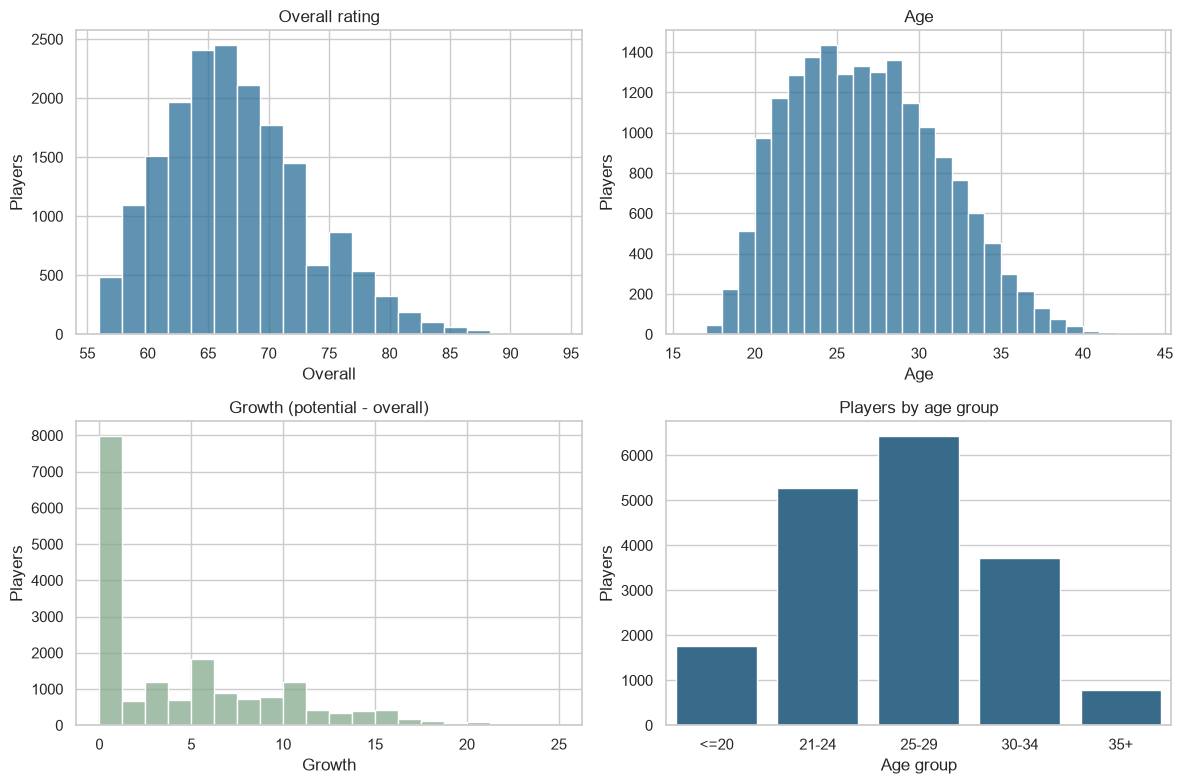

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df["overall"], bins=20, color="#2a6f97", ax=axes[0, 0])
axes[0, 0].set(title="Overall rating", xlabel="Overall", ylabel="Players")

sns.histplot(df["age"], bins=range(16, 45), color="#2a6f97", ax=axes[0, 1])
axes[0, 1].set(title="Age", xlabel="Age", ylabel="Players")

sns.histplot(df["growth"], bins=20, color="#84a98c", ax=axes[1, 0])
axes[1, 0].set(title="Growth (potential - overall)", xlabel="Growth", ylabel="Players")

sns.countplot(data=df, x="age_group", order=age_order, color="#2a6f97", ax=axes[1, 1])
axes[1, 1].set(title="Players by age group", xlabel="Age group", ylabel="Players")

plt.tight_layout()
plt.show()


### 3.3 Missing values after cleaning
There were no missing values to start with, and I did not create any. `hits = 0` is not missing data. I am just not using that column.


In [14]:
print(df.isna().sum())


player_id           0
name                0
nationality         0
position            0
overall             0
age                 0
hits                0
potential           0
team                0
primary_position    0
position_group      0
growth              0
age_group           0
is_free_agent       0
is_wonderkid        0
confederation       0
region              0
dtype: int64


---
## 4. Explore the data and answer the three questions

### 4.1 How players are spread out
Some positions have thousands of players and some have almost none. That matters when I compare averages later.


In [15]:
print(df["primary_position"].value_counts())
print()
print(df["position_group"].value_counts())
print()
print(df["age_group"].value_counts().sort_index())


primary_position
ST     3216
CB     2777
CDM    2176
GK     1885
RB     1805
LB     1665
RM     1443
CM     1145
LM      743
CAM     412
RWB     321
RW      222
LW       76
LWB      57
CF       38
Name: count, dtype: int64

position_group
Defender      6625
Midfielder    5919
Forward       3552
Goalkeeper    1885
Name: count, dtype: int64

age_group
<=20     1757
21-24    5273
25-29    6433
30-34    3729
35+       789
Name: count, dtype: int64


### 4.2 Groupby summaries


In [16]:
df.groupby("age_group", observed=True).agg(
    players=("player_id", "count"),
    avg_overall=("overall", "mean"),
    avg_potential=("potential", "mean"),
    avg_growth=("growth", "mean"),
    wonderkids=("is_wonderkid", "sum"),
).round(2)


,players,avg_overall,avg_potential,avg_growth,wonderkids
age_group,,,,,
<=20,1757,62.50,76.24,13.74,101
21-24,5273,65.61,73.85,8.24,46
25-29,6433,68.51,70.46,1.95,0
30-34,3729,69.38,69.40,0.02,0
35+,789,69.01,69.01,0.00,0


In [17]:
df.groupby("primary_position", observed=True).agg(
    players=("player_id", "count"),
    avg_overall=("overall", "mean"),
    avg_growth=("growth", "mean"),
    avg_age=("age", "mean"),
).sort_values("avg_overall", ascending=False).round(2)


,players,avg_overall,avg_growth,avg_age
primary_position,,,,
CF,38,70.13,5.55,24.87
CDM,2176,68.09,4.17,26.62
RM,1443,67.71,4.48,25.72
CB,2777,67.70,4.15,26.97
LM,743,67.62,4.63,25.63
ST,3216,67.52,4.32,26.26
RW,222,67.24,6.54,24.01
CAM,412,67.23,5.79,24.89
RWB,321,66.71,3.80,26.33


### 4.3 The three proposal questions

#### Q1 – Age, rating, and growth
I grouped by exact age so I can see when overall goes up and when potential comes down.


In [18]:
q1 = df.groupby("age").agg(
    players=("player_id", "count"),
    avg_overall=("overall", "mean"),
    avg_potential=("potential", "mean"),
    avg_growth=("growth", "mean"),
).round(2)

q1


,players,avg_overall,avg_potential,avg_growth
age,,,,
17,45,60.69,78.53,17.84
18,223,60.94,78.05,17.11
19,515,61.41,76.55,15.13
20,974,63.51,75.55,12.04
21,1172,63.58,74.62,11.04
22,1289,65.21,74.45,9.24
23,1376,66.06,73.75,7.69
24,1436,67.19,72.78,5.59
25,1294,67.54,71.96,4.42


In [19]:
print(q1.sort_values("avg_overall", ascending=False).head(8))
print()
print("First age where average growth is under 1:", q1[q1["avg_growth"] < 1].index.min())
print("Average overall at 17:", q1.loc[17, "avg_overall"])
print("Average overall at 28:", q1.loc[28, "avg_overall"])
print("Average potential at 17:", q1.loc[17, "avg_potential"])
print("Players age 40+:", q1.loc[40:, "players"].sum())


     players  avg_overall  avg_potential  avg_growth
age                                                 
42         4        73.75          73.75        0.00
33       601        69.87          69.87        0.00
35       298        69.56          69.56        0.00
32       764        69.55          69.55        0.00
31       880        69.42          69.44        0.02
36       214        69.33          69.33        0.00
28      1360        69.28          69.79        0.51
34       453        69.18          69.18        0.00

First age where average growth is under 1: 28
Average overall at 17: 60.69
Average overall at 28: 69.28
Average potential at 17: 78.53
Players age 40+: 33


**Q1 answer.** Average overall starts around 61 at age 17 and gets to about 69 by age 28, then it mostly stays there. Potential starts high (about 79 at age 17) and falls toward overall. Average growth drops under 1 point at age 28.

Age 42 has the highest average overall, but there are only 4 players. I think that is just the veterans who are still in the game. Weaker older players are already gone, so that number is not a real peak. For the chart I will not lean on ages with a tiny sample.

For FIFA players this means a 17 year old can still grow a lot, and a 29 year old with 0 growth is basically done.


#### Q2 – Countries and clubs
If I rank every country with no minimum, small countries jump to the top. So I am using a minimum number of players, like I said in the proposal.


In [20]:
def rank_groups(data, col, min_n):
    return (
        data.groupby(col)
        .agg(
            players=("player_id", "count"),
            avg_overall=("overall", "mean"),
            avg_potential=("potential", "mean"),
            top_overall=("overall", "max"),
        )
        .query("players >= @min_n")
        .sort_values("avg_overall", ascending=False)
        .round(2)
    )


print("Countries with at least 50 players")
rank_groups(df, "nationality", 50).head(15)


Countries with at least 50 players


,players,avg_overall,avg_potential,top_overall
nationality,,,,
Brazil,894,71.42,73.35,92
Algeria,53,71.19,73.53,86
Ukraine,63,70.71,75.27,81
Russia,73,70.51,76.18,82
Czech Republic,106,70.43,73.31,82
Portugal,351,70.37,75.05,93
Spain,1055,69.87,74.94,89
Morocco,94,69.79,74.19,86
Bosnia & Herzegovina,60,69.72,72.38,86


In [21]:
print("Countries with at least 100 players")
print(rank_groups(df, "nationality", 100).head(10))
print()
print("Clubs with at least 20 players (no free agents)")
rank_groups(df[~df["is_free_agent"]], "team", 20).head(15)


Countries with at least 100 players
                players  avg_overall  avg_potential  top_overall
nationality                                                     
Brazil              894        71.42          73.35           92
Czech Republic      106        70.43          73.31           82
Portugal            351        70.37          75.05           93
Spain              1055        69.87          74.94           89
Serbia              130        69.61          72.81           85
Croatia             140        69.51          74.21           89
Ivory Coast         106        69.50          73.96           83
Belgium             256        69.18          75.10           91
Argentina           970        69.17          73.31           94
Senegal             123        68.99          73.26           90

Clubs with at least 20 players (no free agents)


,players,avg_overall,avg_potential,top_overall
team,,,,
Juventus,23,83.04,84.61,93
FC Bayern München,23,81.57,85.65,91
Napoli,26,79.73,82.15,88
Real Madrid,33,79.61,85.30,91
Paris Saint-Germain,30,78.87,82.77,92
Inter,26,78.58,81.81,88
FC Barcelona,33,78.09,84.27,94
Bayer 04 Leverkusen,24,77.92,82.33,84
Manchester City,32,76.88,83.91,91


In [22]:
eng = df[df["nationality"] == "England"]
bra = df[df["nationality"] == "Brazil"]
print("England:", len(eng), "players, avg overall", round(eng["overall"].mean(), 2))
print("Brazil:", len(bra), "players, avg overall", round(bra["overall"].mean(), 2))
print()
print("Most players rated 80+ by country")
print(df[df["overall"] >= 80].groupby("nationality").size().sort_values(ascending=False).head(8))


England: 1496 players, avg overall 65.25
Brazil: 894 players, avg overall 71.42

Most players rated 80+ by country
nationality
Spain        87
Brazil       63
France       60
Germany      37
Argentina    32
Italy        30
England      27
Portugal     23
dtype: int64


In [23]:
print("After the merge, I can also group by confederation")
df.groupby("confederation").agg(
    players=("player_id", "count"),
    countries=("nationality", "nunique"),
    avg_overall=("overall", "mean"),
    avg_potential=("potential", "mean"),
    elite_80plus=("overall", lambda s: (s >= 80).sum()),
).sort_values("avg_overall", ascending=False).round(2)

After the merge, I can also group by confederation


,players,countries,avg_overall,avg_potential,elite_80plus
confederation,,,,,
CAF,1258,47,68.46,72.79,25
CONMEBOL,3994,10,68.07,71.71,127
UEFA,10332,53,67.40,72.35,389
CONCACAF,822,25,66.08,71.20,9
AFC,1532,24,64.13,67.20,2
OFC,43,3,64.02,68.70,0


**Q2 answer.** With a 50 player minimum, Brazil has the highest average overall (about 71.4). Portugal and Spain are also high. If I raise the minimum to 100, Brazil still leads.

England has the most players in the file (1,496) but not the highest average. Spain has the most elite players (87 players rated 80+).

For clubs, Juventus and Bayern Munich are at the top if I require at least 20 players. Bigger squads like Real Madrid and Barcelona look a little lower because they have more lower-rated young players in the file.

After I merged the second file, CONMEBOL (South America) has the highest average overall. UEFA has the most players and the most 80+ ratings, mostly because the file is full of European league squads.

This is why the dashboard needs a minimum-players slider. Otherwise a tiny country can look like the best in the world.


#### Q3 – Position


In [24]:
df.groupby("primary_position", observed=True).agg(
    players=("player_id", "count"),
    avg_overall=("overall", "mean"),
    avg_growth=("growth", "mean"),
    avg_age=("age", "mean"),
    wonderkids=("is_wonderkid", "sum"),
).round(2).sort_values("avg_growth", ascending=False)


,players,avg_overall,avg_growth,avg_age,wonderkids
primary_position,,,,,
LW,76,64.92,8.08,22.59,1
RW,222,67.24,6.54,24.01,11
CM,1145,66.60,6.09,24.83,17
CAM,412,67.23,5.79,24.89,7
CF,38,70.13,5.55,24.87,1
LM,743,67.62,4.63,25.63,8
RM,1443,67.71,4.48,25.72,23
RB,1805,66.64,4.33,26.16,7
LB,1665,66.64,4.32,26.17,8


In [25]:
df.groupby("position_group").agg(
    players=("player_id", "count"),
    avg_overall=("overall", "mean"),
    avg_growth=("growth", "mean"),
    avg_age=("age", "mean"),
).round(2)


,players,avg_overall,avg_growth,avg_age
position_group,,,,
Defender,6625,67.08,4.22,26.51
Forward,3552,67.48,4.56,26.03
Goalkeeper,1885,66.56,4.12,27.73
Midfielder,5919,67.59,4.79,25.81


In [26]:
wonderkids = df[df["is_wonderkid"]].sort_values(["potential", "overall"], ascending=False)
print("Wonderkids (age <= 21 and potential >= 85):", len(wonderkids))
wonderkids[["name", "age", "overall", "potential", "growth", "primary_position", "team", "nationality"]].head(12)


Wonderkids (age <= 21 and potential >= 85): 147


,name,age,overall,potential,growth,primary_position,team,nationality
13,Kylian Mbappé,21,89,95,6,ST,Paris Saint-Germain,France
55,Jadon Sancho,20,86,94,8,RM,Borussia Dortmund,England
115,Kai Havertz,21,84,93,9,RM,Bayer 04 Leverkusen,Germany
418,João Félix,20,80,93,13,ST,Atlético Madrid,Portugal
81,Matthijs de Ligt,20,85,92,7,CB,Juventus,Netherlands
85,Gianluigi Donnarumma,21,85,92,7,GK,Milan,Italy
562,Vinícius Jr.,20,79,92,13,LW,Real Madrid,Brazil
735,Rodrygo,19,78,91,13,RW,Real Madrid,Brazil
997,Sandro Tonali,20,77,91,14,CDM,Brescia,Italy
83,Trent Alexander-Arnold,21,85,90,5,RB,Liverpool,England


**Q3 answer.** Average overall is pretty close across the four position groups. The bigger difference is growth.

CF has the highest average overall, but there are only 38 of them. LW and RW have the most remaining growth and they are younger on average. CMs and CAMs also have more growth left. Goalkeepers are the oldest group and have less growth left.

If someone is looking for a Career Mode bargain, wide attackers and midfielders are the better place to look. If they need a player who is already finished, a defender or goalkeeper with a high overall makes more sense.


---
## 5. Charts for the dashboard

I wrote a filter function first so I can reuse the same filters on each chart. In Streamlit these would be sidebar widgets.


In [27]:
def apply_filters(data, nationalities=None, confederations=None, position_groups=None,
                  age_range=None, exclude_free_agents=False, wonderkids_only=False):
    out = data
    if nationalities is not None:
        out = out[out["nationality"].isin(nationalities)]
    if confederations is not None:
        out = out[out["confederation"].isin(confederations)]
    if position_groups is not None:
        out = out[out["position_group"].isin(position_groups)]
    if age_range is not None:
        out = out[out["age"].between(age_range[0], age_range[1])]
    if exclude_free_agents:
        out = out[~out["is_free_agent"]]
    if wonderkids_only:
        out = out[out["is_wonderkid"]]
    return out


test = apply_filters(df, position_groups=["Forward"], age_range=(17, 24), exclude_free_agents=True)
print(len(test), "forwards age 17-24 with a club, out of", len(df), "players")


1431 forwards age 17-24 with a club, out of 17981 players


### Chart 1 – Average overall and potential by age (Q1)

I am plotting both lines together. The space between them is the remaining growth. I am hiding ages with fewer than 15 players so a couple of old veterans do not mess up the chart.


All players


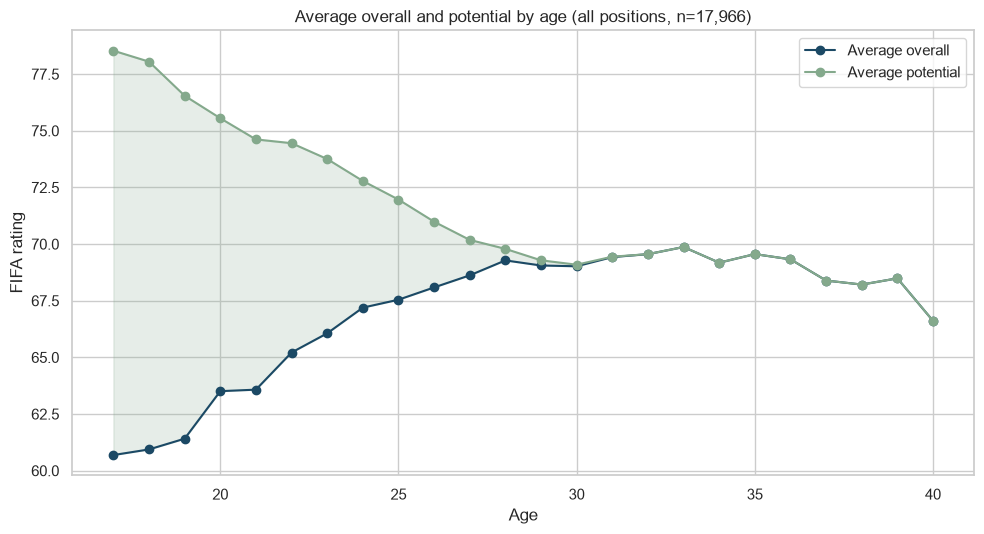

,age,avg_overall,avg_potential,n
0,17,60.69,78.53,45
1,18,60.94,78.05,223
2,19,61.41,76.55,515
3,20,63.51,75.55,974
4,21,63.58,74.62,1172


In [28]:
def plot_rating_by_age(position_groups=None, nationalities=None, age_range=(17, 40)):
    data = apply_filters(df, position_groups=position_groups, nationalities=nationalities, age_range=age_range)
    summary = data.groupby("age").agg(
        avg_overall=("overall", "mean"),
        avg_potential=("potential", "mean"),
        n=("player_id", "count"),
    ).reset_index()
    summary = summary[summary["n"] >= 15]

    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.plot(summary["age"], summary["avg_overall"], marker="o", color="#1b4965", label="Average overall")
    ax.plot(summary["age"], summary["avg_potential"], marker="o", color="#84a98c", label="Average potential")
    ax.fill_between(summary["age"], summary["avg_overall"], summary["avg_potential"], color="#84a98c", alpha=0.2)
    ax.set_xlabel("Age")
    ax.set_ylabel("FIFA rating")
    extra = ", ".join(position_groups) if position_groups else "all positions"
    ax.set_title(f"Average overall and potential by age ({extra}, n={len(data):,})")
    ax.legend()
    plt.tight_layout()
    plt.show()
    return summary


print("All players")
plot_rating_by_age().head()


Forwards only


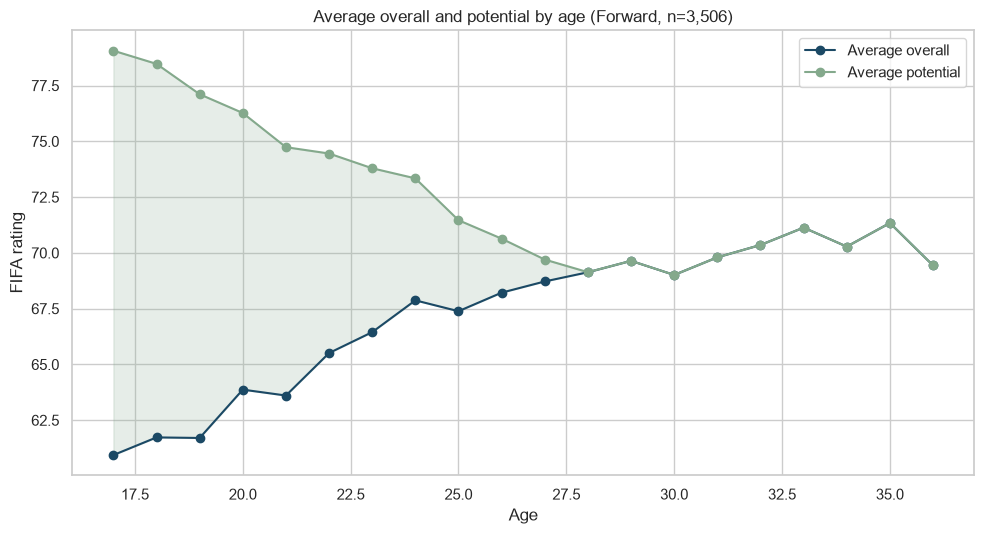

,age,avg_overall,avg_potential,n
0,17,60.94,79.06,16
1,18,61.73,78.47,70
2,19,61.70,77.11,118
3,20,63.87,76.27,215
4,21,63.61,74.74,251
5,22,65.51,74.45,247
6,23,66.45,73.79,255
7,24,67.87,73.34,265
8,25,67.38,71.46,252
9,26,68.22,70.64,259


In [29]:
print("Forwards only")
plot_rating_by_age(position_groups=["Forward"], age_range=(17, 36))


**What it shows.** Overall goes up through the early 20s and flattens around age 28. Potential starts higher and comes down until the two lines meet. After that, players are basically at their ceiling.

**Why it matters.** Career Mode players are looking for that gap between overall and potential. It is wide for teenagers and pretty much gone by the late 20s. When I filter to forwards only, the same pattern shows up, so it is not just one position doing this.


### Chart 2 – Highest rated countries or clubs (Q2)

The bars are average overall. I also print the player count on each bar so a small group cannot hide.


Countries, minimum 50 players


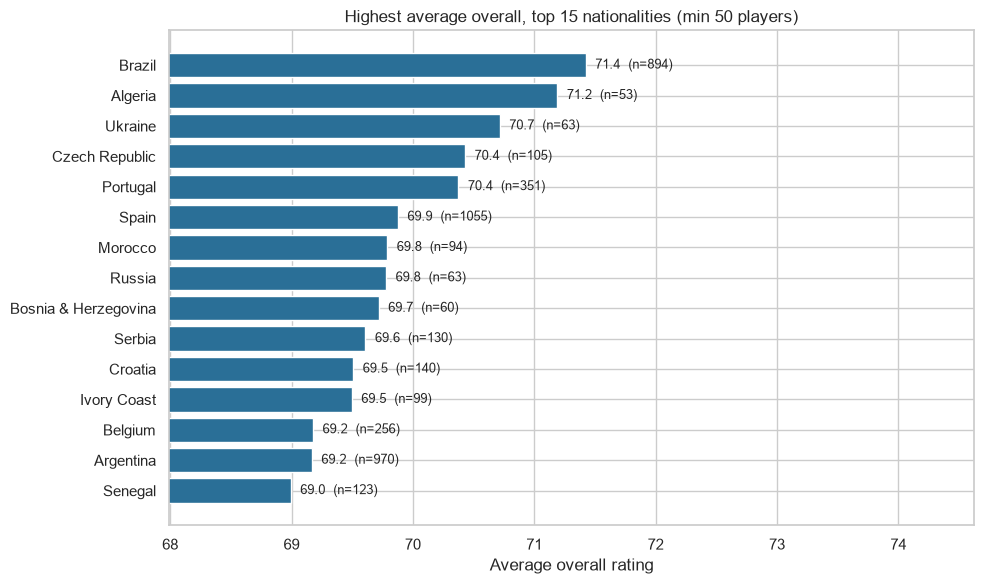

,avg_overall,n
nationality,,
Brazil,71.42,894
Algeria,71.19,53
Ukraine,70.71,63
Czech Republic,70.43,105
Portugal,70.37,351
Spain,69.87,1055
Morocco,69.79,94
Russia,69.78,63


In [30]:
def plot_top_groups(group_col="nationality", min_n=50, top_n=15, exclude_free_agents=True):
    data = apply_filters(df, exclude_free_agents=exclude_free_agents)
    summary = (
        data.groupby(group_col)
        .agg(avg_overall=("overall", "mean"), n=("player_id", "count"))
        .query("n >= @min_n")
        .sort_values("avg_overall")
        .tail(top_n)
    )

    fig, ax = plt.subplots(figsize=(10, 6))
    bars = ax.barh(summary.index.astype(str), summary["avg_overall"], color="#2a6f97")
    for bar, (_, row) in zip(bars, summary.iterrows()):
        ax.text(bar.get_width() + 0.08, bar.get_y() + bar.get_height() / 2,
                f"{row['avg_overall']:.1f}  (n={int(row['n'])})", va="center", fontsize=9)
    label = "nationalities" if group_col == "nationality" else "clubs"
    ax.set_title(f"Highest average overall, top {top_n} {label} (min {min_n} players)")
    ax.set_xlabel("Average overall rating")
    ax.set_xlim(summary["avg_overall"].min() - 1, summary["avg_overall"].max() + 3.2)
    plt.tight_layout()
    plt.show()
    return summary.sort_values("avg_overall", ascending=False)


print("Countries, minimum 50 players")
plot_top_groups("nationality", min_n=50).head(8)


Same chart but minimum 100 players


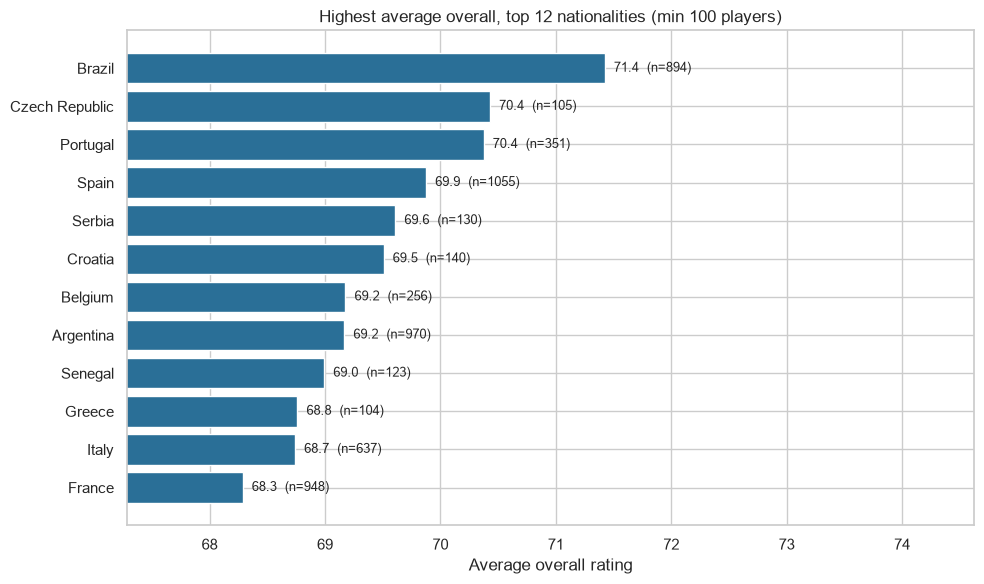

,avg_overall,n
nationality,,
Brazil,71.42,894
Czech Republic,70.43,105
Portugal,70.37,351
Spain,69.87,1055
Serbia,69.61,130
Croatia,69.51,140
Belgium,69.18,256
Argentina,69.17,970
Senegal,68.99,123


In [31]:
print("Same chart but minimum 100 players")
plot_top_groups("nationality", min_n=100, top_n=12)


Clubs, minimum 20 players


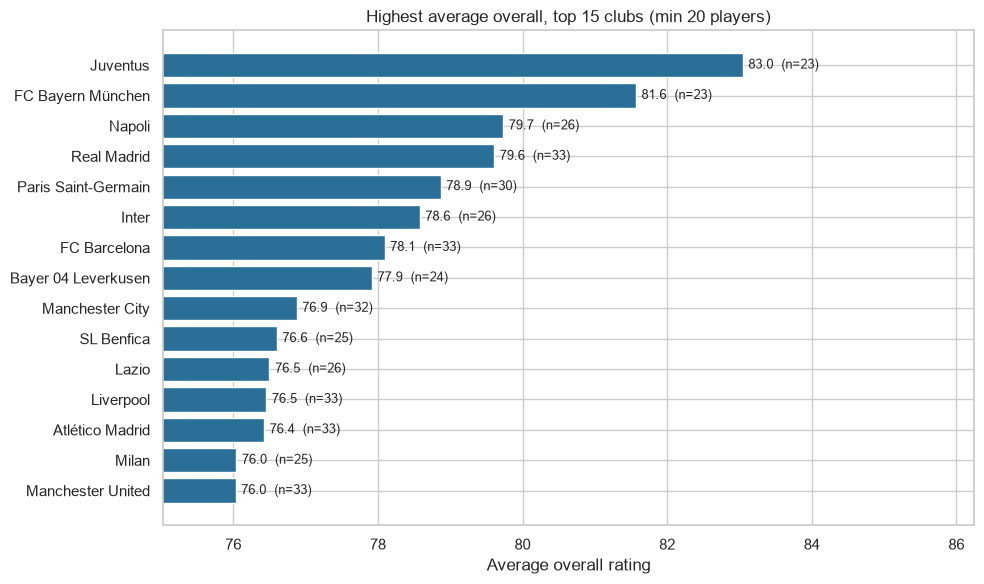

,avg_overall,n
team,,
Juventus,83.04,23
FC Bayern München,81.57,23
Napoli,79.73,26
Real Madrid,79.61,33
Paris Saint-Germain,78.87,30
Inter,78.58,26
FC Barcelona,78.09,33
Bayer 04 Leverkusen,77.92,24
Manchester City,76.88,32


In [32]:
print("Clubs, minimum 20 players")
plot_top_groups("team", min_n=20)


**What it shows.** Brazil is first among countries with at least 50 players. When I move the cutoff to 100, some smaller countries drop off and Brazil is still first. Switching to clubs shows Juventus and Bayern at the top.

**Why it matters.** People argue about which country or club is “best.” This chart makes them use the same rule: average rating, but only if there are enough players. That is the filter I want on the dashboard.


### Chart 3 – Rating and growth by position (Q3)


All ages


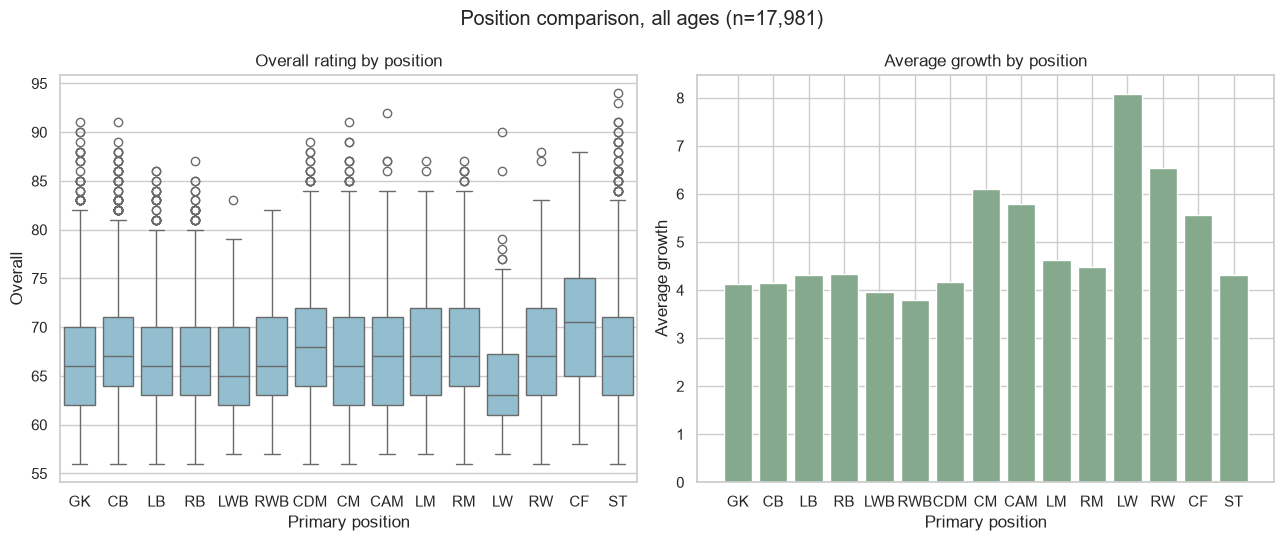

In [33]:
def plot_by_position(age_range=None, min_n=30):
    data = apply_filters(df, age_range=age_range)
    counts = data["primary_position"].value_counts()
    keep = counts[counts >= min_n].index
    plot_df = data[data["primary_position"].isin(keep)].copy()
    plot_df["primary_position"] = plot_df["primary_position"].astype(str)
    order = [p for p in pos_order if p in set(plot_df["primary_position"])]

    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
    sns.boxplot(data=plot_df, x="primary_position", y="overall", order=order, color="#89c2d9", ax=axes[0])
    axes[0].set_title("Overall rating by position")
    axes[0].set_xlabel("Primary position")
    axes[0].set_ylabel("Overall")

    growth = plot_df.groupby("primary_position")["growth"].mean().reindex(order)
    axes[1].bar(growth.index.astype(str), growth.values, color="#84a98c")
    axes[1].set_title("Average growth by position")
    axes[1].set_xlabel("Primary position")
    axes[1].set_ylabel("Average growth")

    title_age = f"ages {age_range[0]}-{age_range[1]}" if age_range else "all ages"
    fig.suptitle(f"Position comparison, {title_age} (n={len(plot_df):,})")
    plt.tight_layout()
    plt.show()


print("All ages")
plot_by_position()


Ages 17 to 23 only


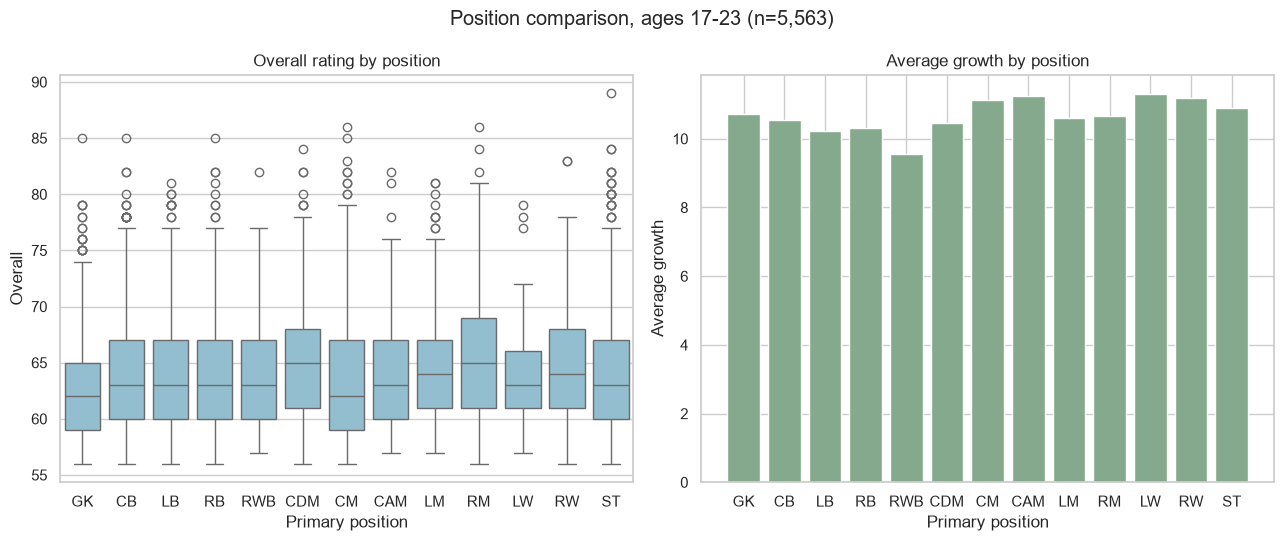

In [34]:
print("Ages 17 to 23 only")
plot_by_position(age_range=(17, 23))


**What it shows.** The overall boxes are pretty similar. Growth is not. LW, RW, CAM, and CM have more unused potential. If I look at ages 17–23 only, every growth bar gets taller, but those same positions are still the highest.

**Why it matters.** This is the “where should I look?” chart. If I want a player who can still rise, I am looking at attackers and midfielders, not veteran goalkeepers.


I also made a list of wonderkids. This can be a table in the app under the charts. It is not one of my three main charts.


In [35]:
wk = apply_filters(df, wonderkids_only=True, exclude_free_agents=True)
print(len(wk), "wonderkids with a club")
wk.sort_values(["potential", "overall"], ascending=False)[
    ["name", "age", "overall", "potential", "growth", "primary_position", "team", "nationality"]
].head(15)


146 wonderkids with a club


,name,age,overall,potential,growth,primary_position,team,nationality
13,Kylian Mbappé,21,89,95,6,ST,Paris Saint-Germain,France
55,Jadon Sancho,20,86,94,8,RM,Borussia Dortmund,England
115,Kai Havertz,21,84,93,9,RM,Bayer 04 Leverkusen,Germany
418,João Félix,20,80,93,13,ST,Atlético Madrid,Portugal
81,Matthijs de Ligt,20,85,92,7,CB,Juventus,Netherlands
85,Gianluigi Donnarumma,21,85,92,7,GK,Milan,Italy
562,Vinícius Jr.,20,79,92,13,LW,Real Madrid,Brazil
735,Rodrygo,19,78,91,13,RW,Real Madrid,Brazil
997,Sandro Tonali,20,77,91,14,CDM,Brescia,Italy
83,Trent Alexander-Arnold,21,85,90,5,RB,Liverpool,England


---
## 6. Which charts go in the dashboard?

I am keeping the three charts from Section 5. Each one answers one question from the proposal, and the filters actually change them.

| Chart | Question | Filters I want |
|---|---|---|
| 1. Overall vs potential by age | Q1 | Position group, nationality, confederation, age |
| 2. Top countries or clubs | Q2 | Nation vs club, minimum players, hide free agents |
| 3. Rating and growth by position | Q3 | Age range, nationality |

The histograms in Section 3 were only to understand the data. The wonderkid list can go under the charts as a table.

For the KPI cards I would show: number of players, average overall, average potential, and average growth. Those should follow the same filters.


---
## 7. Save the dashboard dataset

I am saving a smaller clean CSV for the Streamlit app. I am keeping all players because the filters in the app can hide rows. I only dropped columns I do not need (like hits). Confederation and region stay because they came from the merge.


In [36]:
dash_cols = [
    "player_id", "name", "nationality", "confederation", "region", "team", "position",
    "primary_position", "position_group", "age", "age_group",
    "overall", "potential", "growth", "is_free_agent", "is_wonderkid",
]

dash = df[dash_cols].copy()
dash["primary_position"] = dash["primary_position"].astype(str)
dash["age_group"] = dash["age_group"].astype(str)
dash = dash.sort_values(["overall", "potential"], ascending=False).reset_index(drop=True)
dash.to_csv(DASHBOARD_FILE, index=False)

size_mb = os.path.getsize(DASHBOARD_FILE) / 1_048_576
print("Saved", DASHBOARD_FILE)
print("Shape:", dash.shape)
print("Size:", round(size_mb, 2), "MB")
print("Under 25 MB:", size_mb < 25)


Saved dashboard_data.csv
Shape: (17981, 16)
Size: 1.86 MB
Under 25 MB: True


### 7.1 Reload the file and check it
This is how the Streamlit app will read it.


In [37]:
check = pd.read_csv(DASHBOARD_FILE)
print(check.dtypes)
print()
print("Missing values:")
print(check.isna().sum())
print()
test = check[(check["position_group"] == "Forward") & (check["age"].between(17, 24)) & (~check["is_free_agent"])]
print("Forwards age 17-24 with a club:", len(test))
print("Average overall:", round(test["overall"].mean(), 2))
print("Wonderkids:", int(check["is_wonderkid"].sum()))
print("Free agents:", int(check["is_free_agent"].sum()))
check.head()


player_id           int64
name                  str
nationality           str
confederation         str
region                str
team                  str
position              str
primary_position      str
position_group        str
age                 int64
age_group             str
overall             int64
potential           int64
growth              int64
is_free_agent        bool
is_wonderkid         bool
dtype: object

Missing values:
player_id           0
name                0
nationality         0
confederation       0
region              0
team                0
position            0
primary_position    0
position_group      0
age                 0
age_group           0
overall             0
potential           0
growth              0
is_free_agent       0
is_wonderkid        0
dtype: int64

Forwards age 17-24 with a club: 1431
Average overall: 64.99
Wonderkids: 147
Free agents: 211


,player_id,name,nationality,confederation,region,team,position,primary_position,position_group,age,age_group,overall,potential,growth,is_free_agent,is_wonderkid
0,158023,Lionel Messi,Argentina,CONMEBOL,South America,FC Barcelona,ST|CF|RW,ST,Forward,33,30-34,94,94,0,False,False
1,20801,Cristiano Ronaldo,Portugal,UEFA,Europe,Juventus,ST|LW,ST,Forward,35,35+,93,93,0,False,False
2,190871,Neymar Jr,Brazil,CONMEBOL,South America,Paris Saint-Germain,CAM|LW,CAM,Midfielder,28,25-29,92,92,0,False,False
3,200389,Jan Oblak,Slovenia,UEFA,Europe,Atlético Madrid,GK,GK,Goalkeeper,27,25-29,91,93,2,False,False
4,203376,Virgil van Dijk,Netherlands,UEFA,Europe,Liverpool,CB,CB,Defender,29,25-29,91,92,1,False,False


---
## 8. Notes for the Streamlit dashboard

The app should load `dashboard_data.csv`.

**Title:** FIFA 21 Player Explorer

**Audience:** football fans and FIFA Career Mode / Ultimate Team players

**KPIs (update with filters):** player count, average overall, average potential, average growth

**Filters:**
- nationality
- confederation
- position group
- primary position
- age range
- overall range
- hide free agents
- wonderkids only
- rank by country or club
- minimum players for the ranking chart

**Charts:**
1. Line chart of average overall and potential by age (skip ages with fewer than 15 players)
2. Horizontal bar chart of the top 15 countries or clubs by average overall, with the count on the bar
3. Box plot of overall by position, and a bar chart of average growth by position

**Table:** filtered players, sorted by potential then overall

**If filters return 0 rows:** show a warning, do not crash

**Footer:** data is from Kaggle / fifaindex.com. These are FIFA 21 video game ratings, not real match stats. Some clubs may be out of date.

Libraries I will need later: `streamlit`, `pandas`, `numpy`, `matplotlib`, `seaborn`


---
## Summary

- **Q1:** Ratings go up from about 61 at age 17 to about 69 at age 28. After that, most players have no growth left.
- **Q2:** Brazil has the highest average among large countries. Spain has the most 80+ players. Juventus and Bayern have the highest club averages. After the merge, CONMEBOL has the highest average by confederation.
- **Q3:** Overall is similar by position. LW, RW, CM, and CAM have more room to grow, especially under age 24.

The file I need for Deliverable 3 is `dashboard_data.csv`.
